# Capítulo 5 · Actividad: ¿quién sobrevivió al Titanic?

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/riosinda/ml-course/blob/main/notebooks/exercises/chapter_05/01_actividad_titanic_arbol.ipynb)

Entrena un **árbol de decisión** que prediga si un pasajero sobrevivió (`survived`) y consigue el mejor modelo que puedas. Haz todo el proceso que vimos en clase; el preprocesamiento lo decides tú.

1. **Copia esta notebook a `workspace/`** y trabaja sobre la copia.
2. Si todavía no tienes los datos: `uv run python scripts/download_data.py`

In [24]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn import set_config
from sklearn.impute import SimpleImputer
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix, f1_score,
                             roc_auc_score, roc_curve)
from sklearn.model_selection import (GridSearchCV, StratifiedKFold, cross_val_score, cross_validate,
                                     learning_curve, train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.tree import DecisionTreeClassifier, plot_tree

# Que scikit-learn devuelva DataFrames (con nombres de columna) en lugar de arrays de NumPy
set_config(transform_output="pandas")
sns.set_theme(style="whitegrid")

# Semilla para que los resultados sean reproducibles
SEED = 42
np.random.seed(SEED)

# Carpeta data/ en la raíz del repo: subimos de carpeta en carpeta hasta dar con pyproject.toml
raiz = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists()), Path.cwd())
DATA_DIR = raiz / "data"

In [25]:
# Tu código aquí
titanic = pd.read_csv(DATA_DIR / "titanic.csv")
titanic["sex"] = titanic["sex"].map({"male":1, "female": 0})
titanic["adult_male"] = titanic["adult_male"].map({True:1, False: 0})

#Embarked y embark_town son las mismas columnas
#adult_male esta de mas, no aporta informacion nueva
#alive tambien es una categoria repetiva, tenemos a survived
#pclass y clase tambien son las mismas columnas
#alone esta demas debido a la informacion proporcionada de las columnas sibsp, parch
#Para la columna deck, porque los datos estan muy dispersos como para tomar una decision clara.
#Se opta por eliminarla
titanic = titanic.drop(columns=["embark_town","adult_male","class","alive","alone","deck"])
titanic = titanic.drop_duplicates()


#Para age sera mediante la mediana de cada grupo, en este caso la mediana de mujer, la mediana de hombre
#la mediana de niña y la mediana de niño
titanic["age"] = titanic["age"].fillna(titanic.groupby(["sex","who"])["age"].transform("median"))

#Para embarked, como es una columna con categorias se utilizara la moda
titanic["embarked"] = titanic["embarked"].fillna(titanic["embarked"].mode()[0])

titanic.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,who
0,0,3,1,22.0,1,0,7.2500,S,man
1,1,1,0,38.0,1,0,71.2833,C,woman
2,1,3,0,26.0,0,0,7.9250,S,woman
3,1,1,0,35.0,1,0,53.1000,S,woman
4,0,3,1,35.0,0,0,8.0500,S,man


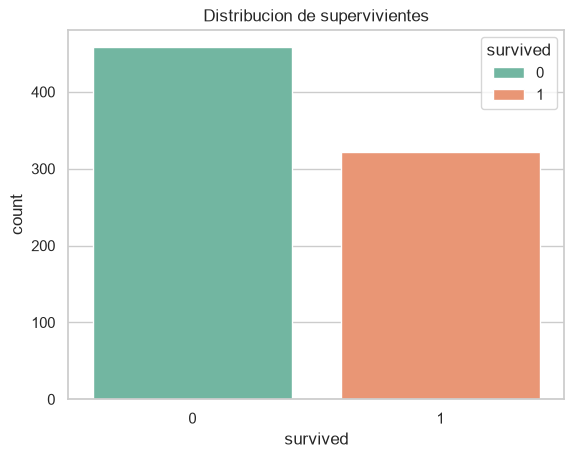

survived
0    0.587179
1    0.412821
Name: proportion, dtype: float64

In [26]:
ax = sns.countplot(data=titanic, x="survived", hue="survived", palette="Set2")
ax.set_title("Distribucion de supervivientes")
plt.show()

titanic["survived"].value_counts(normalize=True)

## Aqui vemos que tenemos una distribución un poco homogenea, masomenos de un 60% - 40% Entonces no se hace nada, si tuvieramos un 90% y un 10% penalizaríamos con accuracy un valor de la clase minotoria

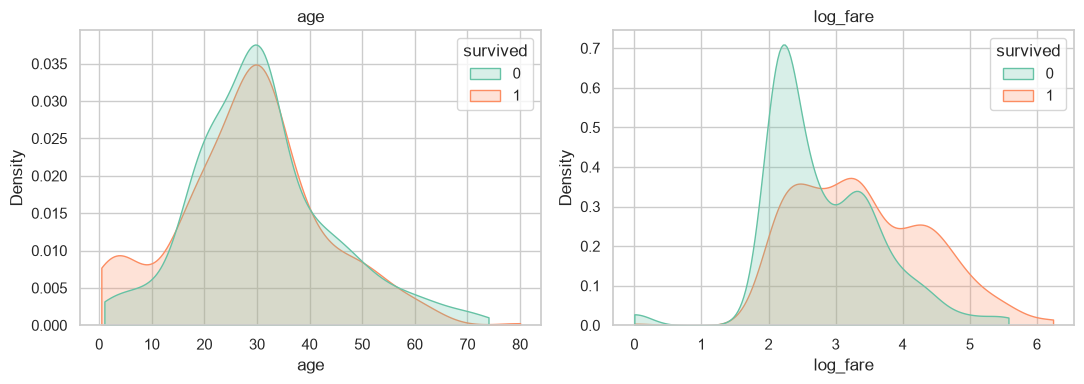

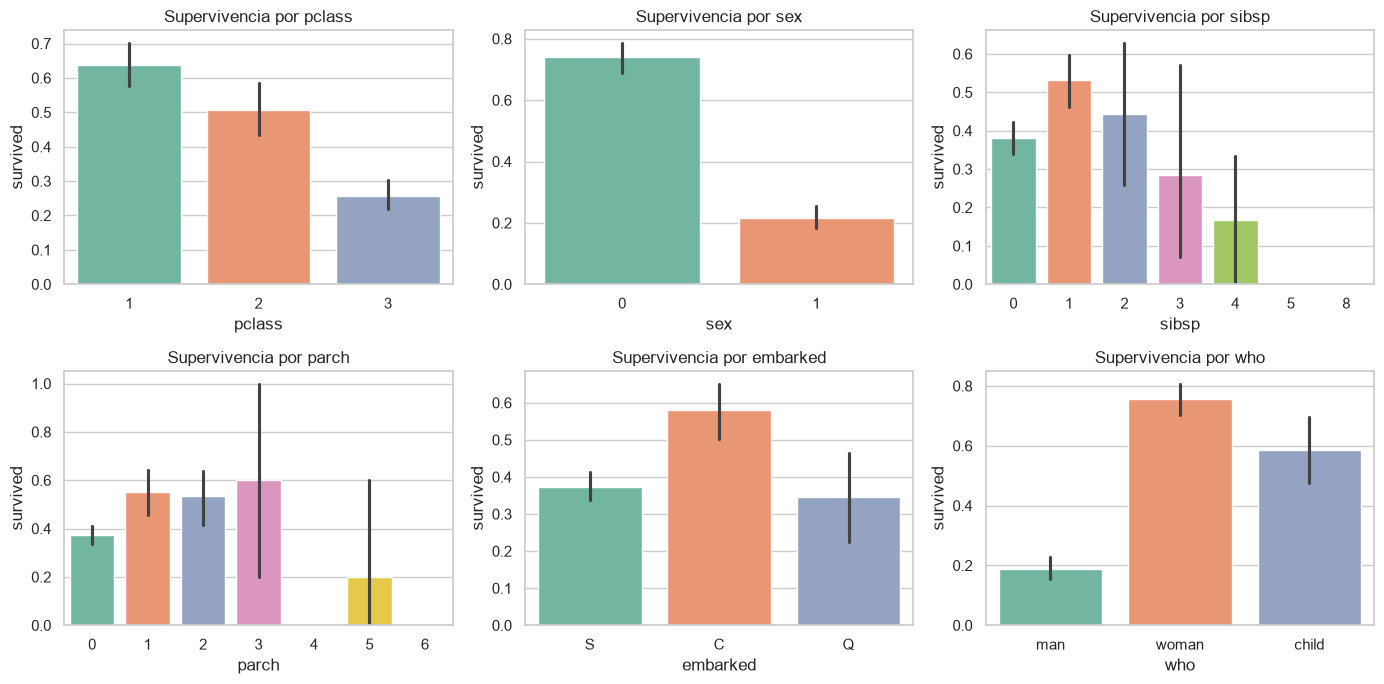

In [27]:
#Como nuestra variable objetivo es survived, entonces vamos a basar las graficas
#en survivded y graficar su respectiva dependiendo de su tipo de variable
datos = titanic.assign(survived=titanic["survived"].map({0: "no", 1: "sí"}))

datos = titanic.assign(
    log_fare=np.log1p(titanic["fare"]),
)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for variable, ax in zip(["age", "log_fare"], axes):
    sns.kdeplot(data=datos, x=variable, hue="survived", fill=True, palette="Set2",
                common_norm=False, cut=0, ax=ax)
    ax.set_title(variable)
plt.tight_layout()
plt.show()


variables = ["pclass", "sex", "sibsp", "parch", "embarked", "who"]

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for variable, ax in zip(variables, axes.flat):
    sns.barplot(data=titanic, x=variable, y="survived", palette="Set2", hue=variable, legend=False, ax=ax)
    ax.set_title(f"Supervivencia por {variable}")
plt.tight_layout()
plt.show()



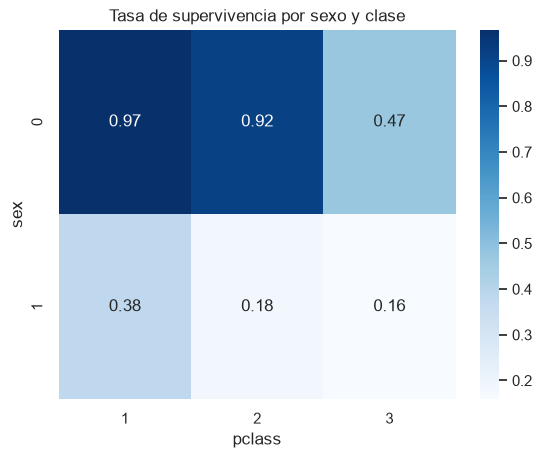

In [28]:
tabla = titanic.pivot_table(index="sex", columns="pclass", values="survived", aggfunc="mean")
sns.heatmap(tabla, annot=True, fmt=".2f", cmap="Blues")
plt.title("Tasa de supervivencia por sexo y clase")
plt.show()

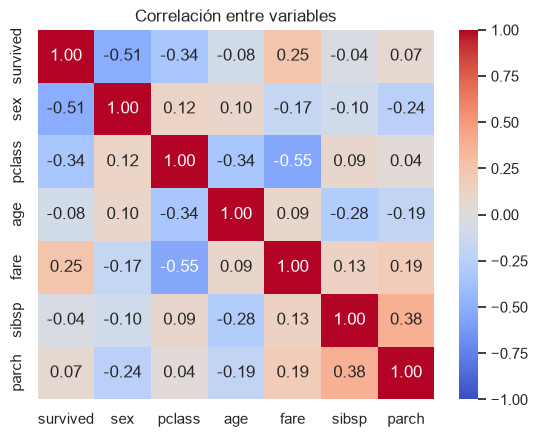

In [29]:
numericas = titanic.assign(sex=titanic["sex"].astype(int))[["survived", "sex", "pclass", "age", "fare", "sibsp", "parch"]]

sns.heatmap(numericas.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlación entre variables")
plt.show()


In [30]:
titanic = titanic.drop_duplicates().reset_index(drop=True)
print("Filas tras eliminar duplicados:", len(titanic))

Filas tras eliminar duplicados: 776


# Lo de arriba fue el preprocesamiento y ahora es el tema de division entre:
## 1) Train y Test, respetando la regla sugerida de 80-20

In [31]:
X = titanic.drop(columns="survived")
y = titanic["survived"]
y = y.astype(str)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED
)

print("Train:", X_train.shape, "| Test:", X_test.shape)
pd.DataFrame({"train": y_train.value_counts(normalize=True), "test": y_test.value_counts(normalize=True)})

Train: (620, 8) | Test: (156, 8)


,train,test
survived,,
0,0.587097,0.589744
1,0.412903,0.410256


In [32]:
columnas = ["age", "fare", "sibsp", "parch"]
datos = X_train[columnas]

q1 = datos.quantile(0.25)
q3 = datos.quantile(0.75)
iqr = q3 - q1
limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

es_outlier = (datos < limite_inferior) | (datos > limite_superior)
es_outlier.sum()

# El IQR marca 13% de outliers en fare, 6% en sibsp, 4% en age y 2% en parch.
# No son errores: 
# son tarifas altas de primera clase, familias numerosas y adultos mayores.
# Se conservan porque el árbol de decisión es robusto a valores extremos.



age      22
fare     77
sibsp    34
parch    12
dtype: int64

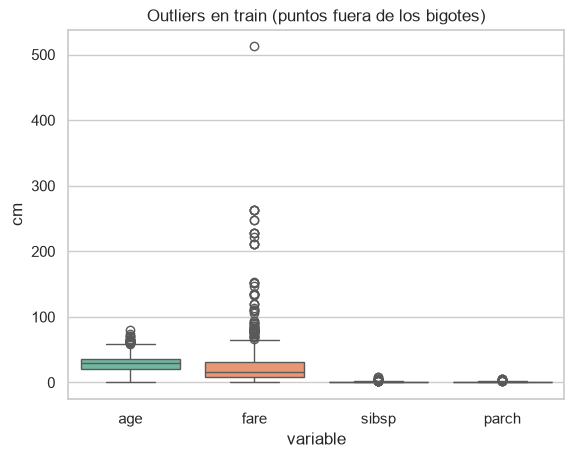

In [33]:
ax = sns.boxplot(data=datos.melt(var_name="variable", value_name="cm"),
                 x="variable", y="cm", hue="variable", palette="Set2")
ax.set_title("Outliers en train (puntos fuera de los bigotes)")
plt.show()

In [34]:
columnas = ["age","fare"]
X_train[columnas] = X_train[columnas].clip(lower=limite_inferior[columnas], upper=limite_superior[columnas], axis=1)
X_test[columnas] = X_test[columnas].clip(lower=limite_inferior[columnas], upper=limite_superior[columnas], axis=1)

print("Outliers en train tras recortar:",
      ((X_train[columnas] < limite_inferior[columnas]) |
       (X_train[columnas] > limite_superior[columnas])).sum().sum())


Outliers en train tras recortar: 0


In [35]:
columnas_texto = ["sex", "embarked", "who"]

X_train = pd.get_dummies(X_train, columns=columnas_texto, drop_first=True, dtype=int)
X_test = pd.get_dummies(X_test, columns=columnas_texto, drop_first=True, dtype=int)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

X_train.dtypes   # comprueba que ya no queda nada de tipo texto


pclass          int64
age           float64
sibsp           int64
parch           int64
fare          float64
sex_1           int64
embarked_Q      int64
embarked_S      int64
who_man         int64
who_woman       int64
dtype: object

In [36]:
columnas = ["age", "fare", "sibsp", "parch", "pclass"]
escalador = StandardScaler()

X_train_esc = X_train.copy()
X_test_esc = X_test.copy()
X_train_esc[columnas] = escalador.fit_transform(X_train[columnas])
X_test_esc[columnas] = escalador.transform(X_test[columnas])


In [37]:
arbol_sin_escalar = DecisionTreeClassifier(random_state=SEED).fit(X_train, y_train)
arbol_escalado = DecisionTreeClassifier(random_state=SEED).fit(X_train_esc, y_train)

print("Accuracy sin escalar:", accuracy_score(y_test, arbol_sin_escalar.predict(X_test)))
print("Accuracy escalado:   ", accuracy_score(y_test, arbol_escalado.predict(X_test_esc)))

Accuracy sin escalar: 0.7243589743589743
Accuracy escalado:    0.7307692307692307


In [38]:
modelo_base = Pipeline([
    ("imputador", SimpleImputer(strategy="median")),
    ("escalador", StandardScaler()),
    ("arbol", DecisionTreeClassifier(random_state=SEED)),
])

modelo_base.fit(X_train, y_train)

arbol_base = modelo_base.named_steps["arbol"]
print("Profundidad:", arbol_base.get_depth(), "| Hojas:", arbol_base.get_n_leaves())
print("Accuracy en train:", accuracy_score(y_train, modelo_base.predict(X_train)))
print("Accuracy en test: ", accuracy_score(y_test, modelo_base.predict(X_test)))

Profundidad: 20 | Hojas: 169
Accuracy en train: 0.9822580645161291
Accuracy en test:  0.7307692307692307


Accuracy en cada fold: [0.702 0.718 0.718 0.75  0.702]
Media: 0.718 ± 0.018


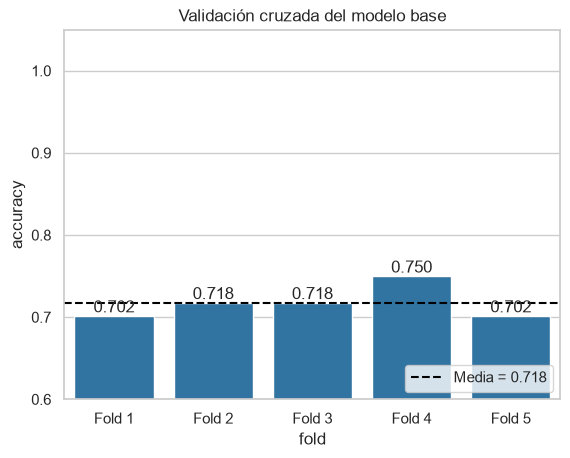

In [39]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

scores_base = cross_val_score(modelo_base, X_train, y_train, cv=cv, scoring="accuracy")
print("Accuracy en cada fold:", scores_base.round(3))
print(f"Media: {scores_base.mean():.3f} ± {scores_base.std():.3f}")

folds = pd.DataFrame({"fold": [f"Fold {i}" for i in range(1, 6)], "accuracy": scores_base})
ax = sns.barplot(data=folds, x="fold", y="accuracy", color="tab:blue")
ax.axhline(scores_base.mean(), color="black", linestyle="--", label=f"Media = {scores_base.mean():.3f}")
ax.bar_label(ax.containers[0], fmt="%.3f")
ax.set_ylim(0.6, 1.05)
ax.set_title("Validación cruzada del modelo base")
ax.legend(loc="lower right")
plt.show()

In [40]:
rejilla = {
    "arbol__criterion": ["gini", "entropy"],
    "arbol__max_depth": [2, 3, 4, 5, None],
    "arbol__min_samples_split": [2, 5, 10],
    "arbol__min_samples_leaf": [1, 2, 4, 8],
}

busqueda = GridSearchCV(modelo_base, rejilla, cv=cv, scoring="accuracy", n_jobs=-1)
busqueda.fit(X_train, y_train)

n_combinaciones = len(busqueda.cv_results_["params"])
print(f"Combinaciones probadas: {n_combinaciones} ({n_combinaciones * cv.get_n_splits()} entrenamientos)")
print("Mejores hiperparámetros:", busqueda.best_params_)
print(f"Mejor accuracy en validación cruzada: {busqueda.best_score_:.3f}")

Combinaciones probadas: 120 (600 entrenamientos)
Mejores hiperparámetros: {'arbol__criterion': 'entropy', 'arbol__max_depth': 5, 'arbol__min_samples_leaf': 4, 'arbol__min_samples_split': 2}
Mejor accuracy en validación cruzada: 0.792


In [41]:
resultados = pd.DataFrame(busqueda.cv_results_)
columnas = ["param_arbol__criterion", "param_arbol__max_depth", "param_arbol__min_samples_split",
            "param_arbol__min_samples_leaf", "mean_test_score", "std_test_score", "rank_test_score"]

resultados[columnas].sort_values("rank_test_score", kind="stable").head(10).round(3)

,param_arbol__criterion,param_arbol__max_depth,param_arbol__min_samples_split,param_arbol__min_samples_leaf,mean_test_score,std_test_score,rank_test_score
102,entropy,5,2,4,0.792,0.022,1
103,entropy,5,5,4,0.792,0.022,1
104,entropy,5,10,4,0.792,0.022,1
0,gini,2,2,1,0.792,0.037,4
1,gini,2,5,1,0.792,0.037,4
2,gini,2,10,1,0.792,0.037,4
3,gini,2,2,2,0.792,0.037,4
4,gini,2,5,2,0.792,0.037,4
5,gini,2,10,2,0.792,0.037,4
6,gini,2,2,4,0.792,0.037,4


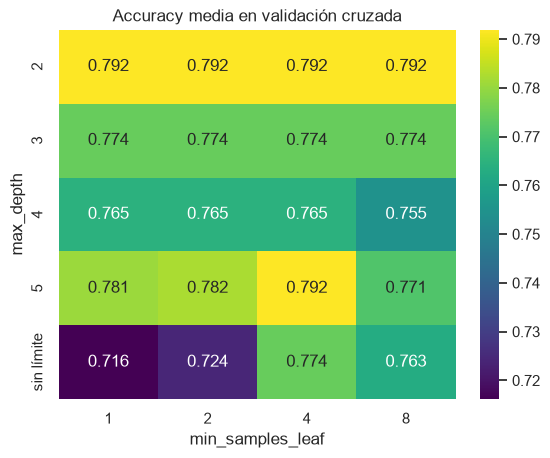

In [42]:
mejor = busqueda.best_params_
filtro = ((resultados["param_arbol__criterion"] == mejor["arbol__criterion"])
          & (resultados["param_arbol__min_samples_split"] == mejor["arbol__min_samples_split"]))

tabla = (resultados[filtro]
         .assign(max_depth=lambda d: d["param_arbol__max_depth"].map(lambda v: "sin límite" if pd.isna(v) else str(int(v))))
         .pivot_table(index="max_depth", columns="param_arbol__min_samples_leaf", values="mean_test_score"))

sns.heatmap(tabla, annot=True, fmt=".3f", cmap="viridis")
plt.title("Accuracy media en validación cruzada")
plt.xlabel("min_samples_leaf")
plt.ylabel("max_depth")
plt.show()

In [43]:
modelo_opt = busqueda.best_estimator_   # ya reentrenado con todo train

arbol_opt = modelo_opt.named_steps["arbol"]
print("Profundidad:", arbol_opt.get_depth(), "| Hojas:", arbol_opt.get_n_leaves())
print("Accuracy en train:", accuracy_score(y_train, modelo_opt.predict(X_train)))
print("Accuracy en test: ", accuracy_score(y_test, modelo_opt.predict(X_test)))

Profundidad: 5 | Hojas: 25
Accuracy en train: 0.8419354838709677
Accuracy en test:  0.8141025641025641


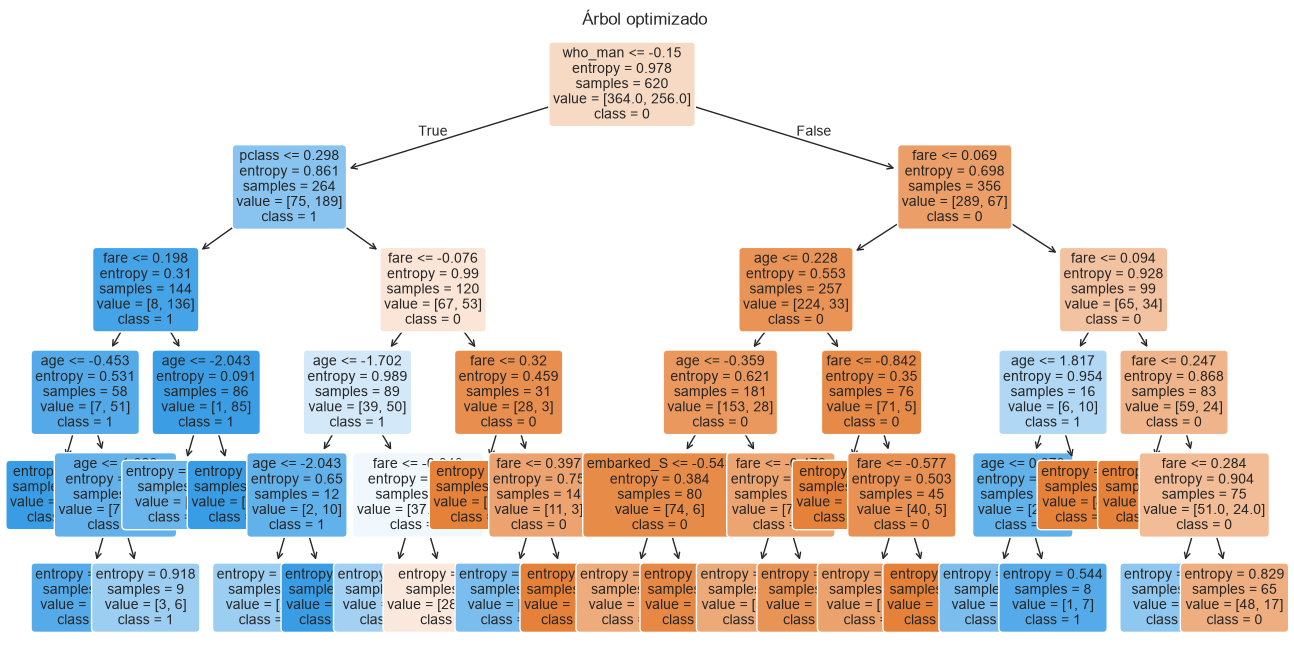

In [44]:
# Visualizar el arbol

plt.figure(figsize=(16, 8))
plot_tree(arbol_opt, feature_names=list(X_train.columns), class_names=list(arbol_opt.classes_),
          filled=True, rounded=True, fontsize=10)
plt.title("Árbol optimizado")
plt.show()

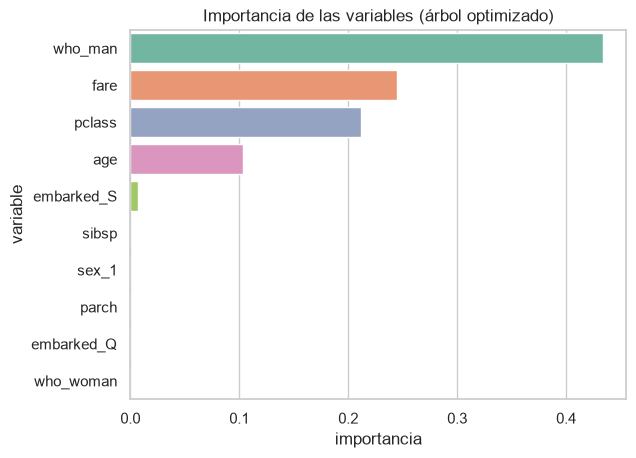

In [46]:
importancias = pd.DataFrame({
    "variable": X_train.columns,
    "importancia": arbol_opt.feature_importances_,
}).sort_values("importancia", ascending=False)

ax = sns.barplot(data=importancias, x="importancia", y="variable", hue="variable", palette="Set2")
ax.set_title("Importancia de las variables (árbol optimizado)")
plt.show()

In [47]:
metricas_cv = {"accuracy": "accuracy", "f1_macro": "f1_macro", "auc_ovr": "roc_auc_ovr"}

filas = []
for nombre, modelo in [("Base (por defecto)", modelo_base), ("Optimizado", modelo_opt)]:
    cv_res = cross_validate(modelo, X_train, y_train, cv=cv, scoring=metricas_cv, return_train_score=True)
    for metrica in metricas_cv:
        for conjunto, clave in [("Train", f"train_{metrica}"), ("Validación", f"test_{metrica}")]:
            for fold, valor in enumerate(cv_res[clave], start=1):
                filas.append({"modelo": nombre, "métrica": metrica, "conjunto": conjunto,
                              "fold": fold, "valor": valor})
cv_resultados = pd.DataFrame(filas)

# Resumen: media ± desviación de cada métrica
resumen_cv = (cv_resultados
              .groupby(["modelo", "conjunto", "métrica"])["valor"]
              .agg(media="mean", desv=lambda s: s.std(ddof=0))   # ddof=0, como NumPy en cross_val_score
              .unstack("métrica")
              .round(3))
resumen_cv

media                      desv          \
métrica                       accuracy auc_ovr f1_macro accuracy auc_ovr   
modelo             conjunto                                                
Base (por defecto) Train         0.986   1.000    0.985    0.001   0.000   
                   Validación    0.718   0.711    0.708    0.018   0.013   
Optimizado         Train         0.840   0.911    0.830    0.007   0.017   
                   Validación    0.792   0.837    0.778    0.022   0.038   

                                        
métrica                       f1_macro  
modelo             conjunto             
Base (por defecto) Train         0.001  
                   Validación    0.018  
Optimizado         Train         0.008  
                   Validación    0.028

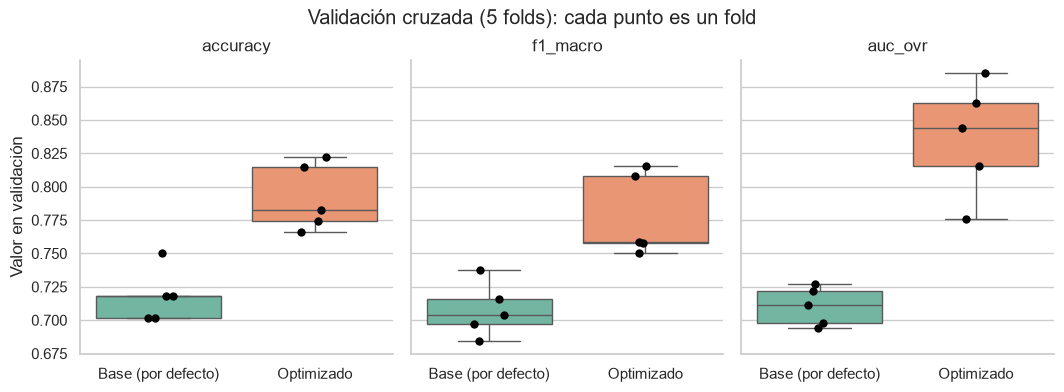

In [48]:
validacion = cv_resultados[cv_resultados["conjunto"] == "Validación"]

g = sns.catplot(data=validacion, x="modelo", y="valor", col="métrica", hue="modelo",
                kind="box", palette="Set2", showfliers=False, height=4, aspect=0.9)
g.map_dataframe(sns.stripplot, x="modelo", y="valor", color="black", size=6, jitter=0.1)
g.set_axis_labels("", "Valor en validación")
g.set_titles("{col_name}")
g.figure.suptitle("Validación cruzada (5 folds): cada punto es un fold", y=1.03)
plt.show()

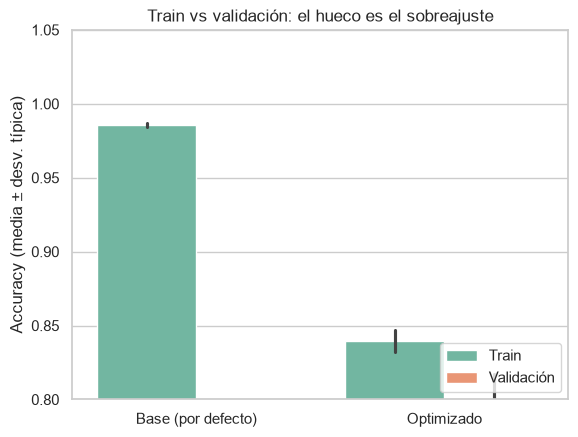

In [49]:
accuracy_cv = cv_resultados[cv_resultados["métrica"] == "accuracy"]

ax = sns.barplot(data=accuracy_cv, x="modelo", y="valor", hue="conjunto", palette="Set2", errorbar="sd")
ax.set_ylim(0.8, 1.05)
ax.set_ylabel("Accuracy (media ± desv. típica)")
ax.set_xlabel("")
ax.set_title("Train vs validación: el hueco es el sobreajuste")
ax.legend(loc="lower right")
plt.show()

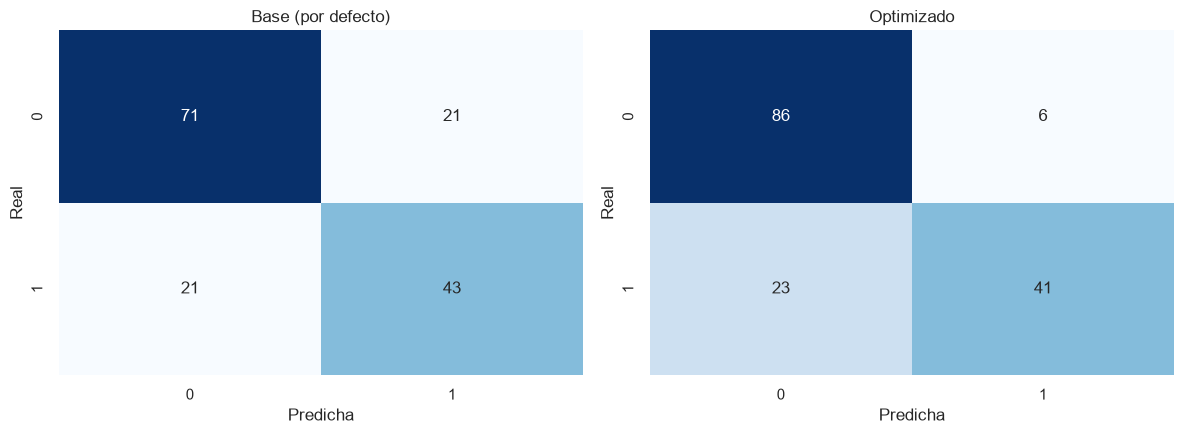

In [50]:
modelos = {"Base (por defecto)": modelo_base, "Optimizado": modelo_opt}
clases = modelo_base.classes_

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for (nombre, modelo), ax in zip(modelos.items(), axes):
    matriz = confusion_matrix(y_test, modelo.predict(X_test), labels=clases)
    sns.heatmap(matriz, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=clases, yticklabels=clases, ax=ax)
    ax.set_title(nombre)
    ax.set_xlabel("Predicha")
    ax.set_ylabel("Real")
plt.tight_layout()
plt.show()

In [51]:
for nombre, modelo in modelos.items():
    print(f"===== {nombre} =====")
    print(classification_report(y_test, modelo.predict(X_test), digits=3))

===== Base (por defecto) =====
              precision    recall  f1-score   support

           0      0.772     0.772     0.772        92
           1      0.672     0.672     0.672        64

    accuracy                          0.731       156
   macro avg      0.722     0.722     0.722       156
weighted avg      0.731     0.731     0.731       156

===== Optimizado =====
              precision    recall  f1-score   support

           0      0.789     0.935     0.856        92
           1      0.872     0.641     0.739        64

    accuracy                          0.814       156
   macro avg      0.831     0.788     0.797       156
weighted avg      0.823     0.814     0.808       156



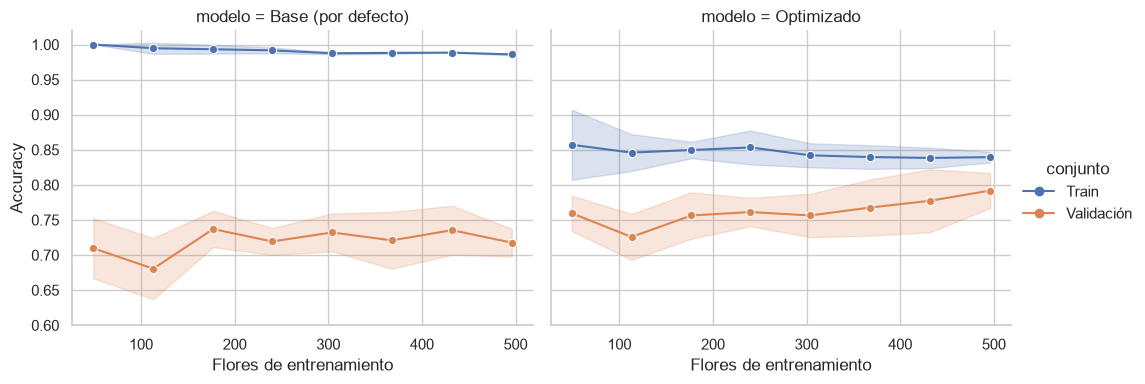

In [52]:
def calcular_curva_aprendizaje(modelo, nombre):
    """Devuelve un DataFrame largo (una fila por tamaño, fold y conjunto) para seaborn."""
    tamaños, scores_train, scores_val = learning_curve(
        modelo, X_train, y_train, cv=cv, scoring="accuracy",
        train_sizes=np.linspace(0.1, 1.0, 8), shuffle=True, random_state=SEED,
    )
    filas = []
    for conjunto, scores in [("Train", scores_train), ("Validación", scores_val)]:
        for tamaño, scores_tamaño in zip(tamaños, scores):
            for score in scores_tamaño:
                filas.append({"modelo": nombre, "conjunto": conjunto, "n_flores": tamaño, "accuracy": score})
    return pd.DataFrame(filas)


curvas = pd.concat([calcular_curva_aprendizaje(m, n) for n, m in modelos.items()])

g = sns.relplot(data=curvas, x="n_flores", y="accuracy", hue="conjunto", col="modelo",
                kind="line", marker="o", errorbar="sd", height=4, aspect=1.3)
g.set_axis_labels("Flores de entrenamiento", "Accuracy")
g.set(ylim=(0.6, 1.02))
plt.show()

In [53]:

probas_opt = modelo_opt.predict_proba(X_test)
pd.DataFrame(probas_opt, columns=clases).round(2).head()

,0,1
0,0.74,0.26
1,0.94,0.06
2,0.55,0.45
3,0.76,0.24
4,0.55,0.45


In [67]:
y_test.dtype, y_test.unique()

X_test

,pclass,age,sibsp,parch,fare,sex_1,embarked_Q,embarked_S,who_man,who_woman
88,1,46.0,1,0,61.1750,1,0,1,1,0
439,3,21.0,0,0,7.2500,1,0,1,1,0
8,3,27.0,0,2,11.1333,0,0,1,0,1
444,3,31.0,0,0,15.1000,1,0,1,1,0
577,3,32.0,1,1,15.5000,0,1,0,0,1
...,...,...,...,...,...,...,...,...,...,...
454,3,28.0,0,0,22.5250,1,0,1,1,0
127,2,23.0,0,0,15.0458,1,0,0,1,0
76,3,30.0,0,0,12.4750,0,0,1,0,1
564,3,41.0,0,5,39.6875,0,0,1,0,1


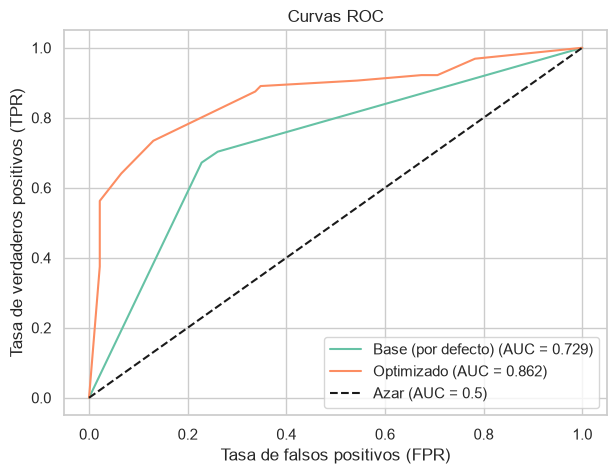

In [59]:
#y = y.astype(int)
# Convertimos el target en una columna binaria por clase (one-vs-rest)
y_test_bin = label_binarize(y_test, classes=clases)

filas = []
for nombre, modelo in modelos.items():
    probas = modelo.predict_proba(X_test)[:, 1]          # probabilidad de sobrevivir
    fpr, tpr, _ = roc_curve(y_test, probas, pos_label="1")
    auc = roc_auc_score(y_test, probas)
    for x, y_ in zip(fpr, tpr):
        filas.append({"modelo": f"{nombre} (AUC = {auc:.3f})", "FPR": x, "TPR": y_})
roc = pd.DataFrame(filas)

fig, ax = plt.subplots(figsize=(7, 5))
sns.lineplot(data=roc, x="FPR", y="TPR", hue="modelo", palette="Set2",
             estimator=None, sort=False, ax=ax)
ax.plot([0, 1], [0, 1], "k--", label="Azar (AUC = 0.5)")
ax.set_title("Curvas ROC")
ax.set_xlabel("Tasa de falsos positivos (FPR)")
ax.set_ylabel("Tasa de verdaderos positivos (TPR)")
ax.legend(loc="lower right")
plt.show()


In [62]:
for nombre, modelo in modelos.items():
    auc = roc_auc_score(y_test, modelo.predict_proba(X_test)[:, 1])
    print(f"{nombre:<20} AUC = {auc:.3f}")


Base (por defecto)   AUC = 0.729
Optimizado           AUC = 0.862


In [64]:
def evaluar(modelo, scores_cv):
    """Métricas principales de un modelo ya entrenado."""
    pred_test = modelo.predict(X_test)
    return {
        "Accuracy train": accuracy_score(y_train, modelo.predict(X_train)),
        "Accuracy CV (media)": scores_cv.mean(),
        "Accuracy CV (desv.)": scores_cv.std(),
        "Accuracy test": accuracy_score(y_test, pred_test),
        "F1 macro test": f1_score(y_test, pred_test, average="macro"),
        "AUC test": roc_auc_score(y_test, modelo.predict_proba(X_test)[:, 1]),
        "Profundidad": modelo.named_steps["arbol"].get_depth(),
        "Hojas": modelo.named_steps["arbol"].get_n_leaves(),
    }


scores_opt = cross_val_score(modelo_opt, X_train, y_train, cv=cv, scoring="accuracy")

reporte = pd.DataFrame({
    "Base (por defecto)": evaluar(modelo_base, scores_base),
    "Optimizado": evaluar(modelo_opt, scores_opt),
}).T

reporte.round(3)

,Accuracy train,Accuracy CV (media),Accuracy CV (desv.),Accuracy test,F1 macro test,AUC test,Profundidad,Hojas
Base (por defecto),0.982,0.718,0.018,0.731,0.722,0.729,20.0,169.0
Optimizado,0.842,0.792,0.022,0.814,0.797,0.862,5.0,25.0


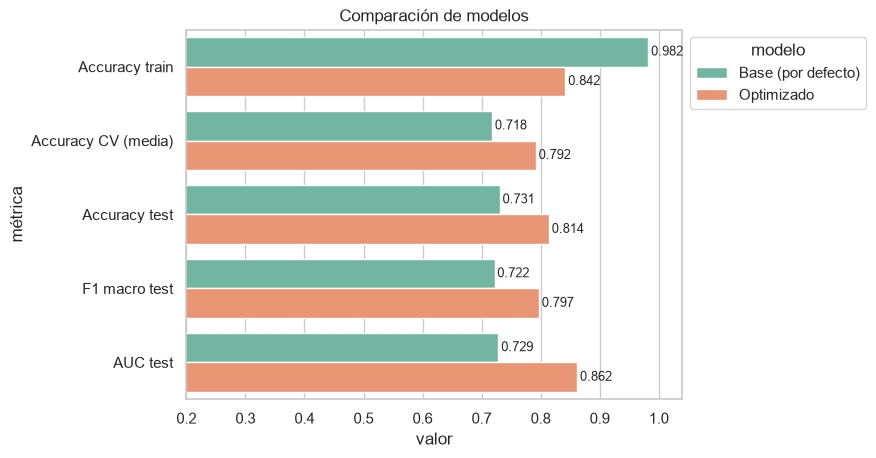

In [68]:
metricas = ["Accuracy train", "Accuracy CV (media)", "Accuracy test", "F1 macro test", "AUC test"]
reporte_largo = (reporte[metricas]
                 .reset_index(names="modelo")
                 .melt(id_vars="modelo", var_name="métrica", value_name="valor"))

ax = sns.barplot(data=reporte_largo, x="valor", y="métrica", hue="modelo", palette="Set2")
ax.set_xlim(0.2, 1.04)
ax.set_title("Comparación de modelos")
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
for contenedor in ax.containers:
    ax.bar_label(contenedor, fmt="%.3f", fontsize=9, padding=2)
plt.show()